In [1]:
import h3
import h3coco as coco

target_cells = coco.cells_for_state('california', 7)

In [2]:
'8049fffffffffff'
'81483ffffffffff'
'824807fffffffff'

cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'}

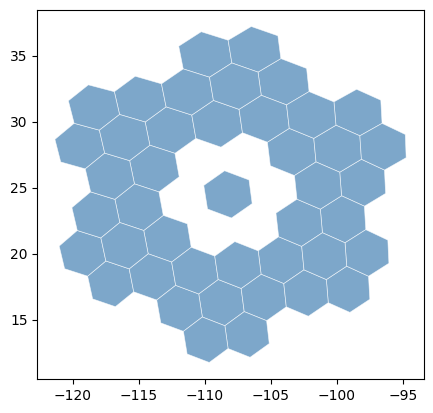

In [3]:
coco.plot_cells(cells)

In [4]:
from dataclasses import dataclass
import matplotlib.pyplot as plt

def plot_signed_cells(cells: dict[str, int], ax=None):
    """Plot cells with +1 values in blue and -1 values in red.
    
    Cells are plotted in resolution order (low to high) so larger cells appear under smaller ones.
    """
    if ax is None:
        ax = plt.gca()
    
    # Sort by resolution (ascending) so lower res cells are drawn first (underneath)
    sorted_cells = sorted(cells.items(), key=lambda kv: h3.get_resolution(kv[0]))
    
    for cell, sign in sorted_cells:
        if sign > 0:
            coco.plot_cells([cell], ax=ax, facecolor='steelblue', edgecolor='white', alpha=1.0)
        else:
            coco.plot_cells([cell], ax=ax, facecolor='indianred', edgecolor='white', alpha=1.0)
    
    return ax


@dataclass
class Janus:
    root: str  # root/parent cell
    
    child_res: int
    local_target_cells: set[str]
    pos: dict[str, int]
    neg: dict[str, int]
    
    def check(self):
        for h in self.local_target_cells:
            assert h3.get_resolution(h) == self.child_res

        desc = set(h3.cell_to_children(self.root, self.child_res))
        assert self.local_target_cells <= desc

        pos = coco.co_uncompact(self.pos, self.child_res)
        neg = coco.co_uncompact(self.neg, self.child_res)
        assert len(pos & neg) == 0
        assert desc == pos | neg

    def plot(self):
        fig, (ax_pos, ax_neg) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
        
        for ax in (ax_pos, ax_neg):
            ax.set_xticks([])
            ax.set_yticks([])
        
        plot_signed_cells(self.pos, ax=ax_pos)
        plot_signed_cells(self.neg, ax=ax_neg)
        
        fig.tight_layout()
        return fig

In [5]:
jan = Janus(
    root = '8049fffffffffff',
    child_res = 2,
    local_target_cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'},
    pos = {'8049fffffffffff': 1, '81483ffffffffff': -1, '824807fffffffff': 1},
    neg = {'81483ffffffffff': 1, '824807fffffffff': -1},
)

jan.check()

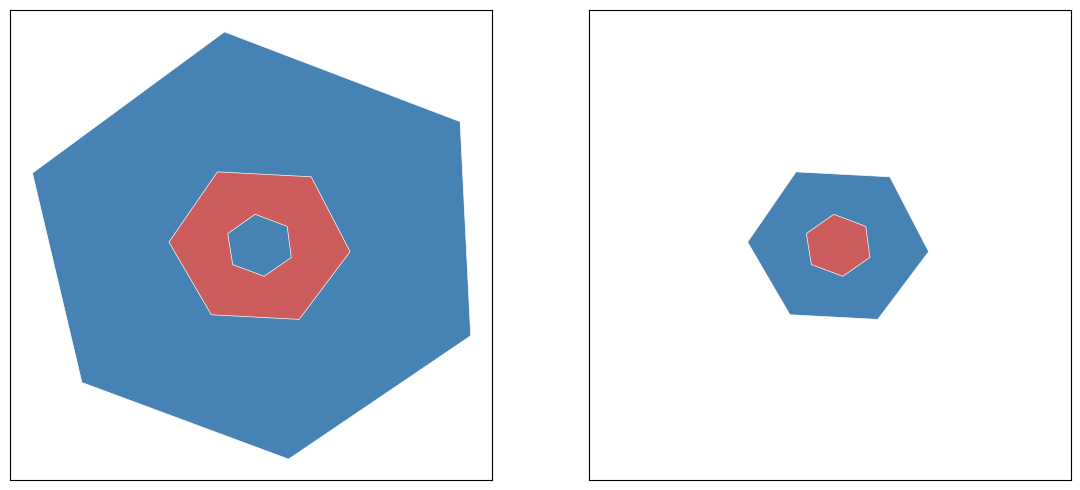

In [6]:
jan.plot();

In [84]:
# complement. unpack. counter?

co_uncompact(jan.pos, 2)

{'824807fffffffff',
 '824847fffffffff',
 '82484ffffffffff',
 '824857fffffffff',
 '82485ffffffffff',
 '824867fffffffff',
 '82486ffffffffff',
 '824877fffffffff',
 '824887fffffffff',
 '82488ffffffffff',
 '824897fffffffff',
 '82489ffffffffff',
 '8248a7fffffffff',
 '8248affffffffff',
 '8248b7fffffffff',
 '8248c7fffffffff',
 '8248cffffffffff',
 '8248d7fffffffff',
 '8248dffffffffff',
 '8248e7fffffffff',
 '8248effffffffff',
 '8248f7fffffffff',
 '824907fffffffff',
 '82490ffffffffff',
 '824917fffffffff',
 '82491ffffffffff',
 '824927fffffffff',
 '82492ffffffffff',
 '824937fffffffff',
 '824947fffffffff',
 '82494ffffffffff',
 '824957fffffffff',
 '82495ffffffffff',
 '824967fffffffff',
 '82496ffffffffff',
 '824977fffffffff',
 '824987fffffffff',
 '82498ffffffffff',
 '824997fffffffff',
 '82499ffffffffff',
 '8249a7fffffffff',
 '8249affffffffff',
 '8249b7fffffffff'}

In [18]:
len(target)

74445

In [15]:
best_pos_under = {
    c: {c: 1}
    for c in cells
}

def up(best_pos_under, all_cells):
    parents = set(
        h3.cell_to_parent(c)
        for c in cells
    )
    for p in parents:
        children = set(h3.cell_to_children(p))
        pos_children = cells & children
    

In [12]:
cells = set(cells)

parents = set(
    h3.cell_to_parent(c)
    for c in cells
)

pos = {}
neg = {}
for p in parents:
    children = set(h3.cell_to_children(p))
    pos_children = children & cells
    neg_children = children - cells
    assert children == pos_children | neg_children
    if len(pos_children) <= 4:
        pos[p] = pos_children
        neg[p] = 
    else:
        